# 02 · 状态空间与 LQR：把“推多少”变成明确的设计问题

上一篇的 PD 已经同时使用位置与速度。这一篇把它统一写成状态反馈，再通过极点配置和最优控制来选增益。

**学习成果：** 检查可控性与可观性；区分连续和离散稳定性；推导有限时域 Riccati 递推；理解无限时域 LQR 与 Lyapunov 函数的联系。


[00 学习地图与小车建模](00_学习地图与小车建模.ipynb) · [01 经典控制与PID](01_经典控制与PID.ipynb) · [02 状态空间与LQR](02_状态空间与LQR.ipynb) · [03 观测器与Kalman滤波](03_观测器与Kalman滤波.ipynb) · [04 从有限时域优化到MPC](04_从有限时域优化到MPC.ipynb) · [05 综合实验与进阶路线](05_综合实验与进阶路线.ipynb)

每篇可独立运行；本篇内按顺序执行。图中英文标签对应正文中文术语，避免依赖本机中文字体。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, linalg

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 3.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
DT = 0.1
MASS, DRAG = 1.0, 0.4
C = np.array([[1.0, 0.0]])

def model(mass=MASS, drag=DRAG):
    Ac = np.array([[0.0, 1.0], [0.0, -drag / mass]])
    Bc = np.array([[0.0], [1.0 / mass]])
    A, B, _, _, _ = signal.cont2discrete((Ac, Bc, C, np.zeros((1, 1))), DT)
    return A, B

A, B = model()
b = B[:, 0]
REF = np.array([1.0, 0.0])

def rollout(policy, steps=120, x0=(0.0, 0.0), disturbance=None, plant=None):
    Ap, Bp = (A, B) if plant is None else plant
    xs, us = [np.array(x0, dtype=float)], []
    for k in range(steps):
        u = float(policy(xs[-1].copy(), k))
        d = 0.0 if disturbance is None else float(disturbance(k))
        xs.append(Ap @ xs[-1] + Bp[:, 0] * (u + d))
        us.append(u)
    return np.asarray(xs), np.asarray(us)

def plot_runs(runs, title, wall=None):
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
    for label, (xs, us) in runs.items():
        axes[0].plot(np.arange(len(xs))*DT, xs[:, 0], label=label)
        axes[1].plot(np.arange(len(xs))*DT, xs[:, 1], label=label)
        axes[2].step(np.arange(len(us))*DT, us, where="post", label=label)
    axes[0].axhline(REF[0], color="black", ls=":", label="target")
    if wall is not None:
        axes[0].axhline(wall, color="firebrick", ls="--", label="position limit")
    for ax, label in zip(axes, ["position [m]", "velocity [m/s]", "force [N]"]):
        ax.set_ylabel(label)
    axes[0].legend(ncol=3, fontsize=8)
    axes[-1].set_xlabel("time [s]")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


## 1. 从误差标量到状态向量

$$x_{k+1}=Ax_k+Bu_k,\quad y_k=Cx_k.$$

目标 $x_r=[1,0]^T$、$u_r=0$ 满足 $x_r=Ax_r+Bu_r$。定义状态偏差 $e_k=x_k-x_r$，于是：

$$e_{k+1}=Ae_k+B\delta u_k,\quad \delta u_k=u_k-u_r.$$

本篇 $e$ 是“实际减目标”，与上一篇 PID 的标量误差“目标减位置”符号相反；代码始终显式写出方向。线性状态反馈：

$$\delta u_k=-Ke_k,\quad e_{k+1}=(A-BK)e_k.$$

当 $K=[K_p,K_d]$ 时，这就是上一篇使用真实速度的 PD。现代控制将这类反馈组织成能推广到多状态、多输入的设计框架。

### 可控性：推力是否能影响所有需要控制的状态？

两维系统的可控矩阵 $\mathcal C=[B,AB]$。若秩为 2，任意状态方向都能通过一段输入序列到达。它不意味着“在有限推力下，任意状态都能安全停靠”。约束可达性是更强的问题。

### 可观性：只有位置，能否重建速度？

可观矩阵 $\mathcal O=[C^T,(CA)^T]^T$。秩为 2，表示结合连续几次已知输入和位置测量，可以区分不同初始状态。单次测量看不见速度，时间序列可以。


In [2]:
controllability = np.column_stack([B, A@B])
observability = np.vstack([C, C@A])
print("Controllability:\n", controllability)
print("Observability:\n", observability)
assert np.linalg.matrix_rank(controllability) == 2
assert np.linalg.matrix_rank(observability) == 2
print("Both ranks = 2")


Controllability:
 [[0.0049 0.0145]
 [0.098  0.0942]]
Observability:
 [[1.    0.   ]
 [1.    0.098]]
Both ranks = 2


## 2. 极点配置：先决定衰减速度，再解反馈增益

对离散系统，特征值 $\lambda$ 对应 $\lambda^k$ 的自然响应。$|\lambda|<1$ 才会衰减。离散极点 0.8 表示每一步缩小到约 80%，不是“每秒缩小到 80%”。

给定两个不同的连续期望极点 $s_1=-1.5,s_2=-2.0$，可用 $z_i=e^{s_iT_s}$ 转成离散期望极点，然后计算 K。快极点往往需要更大输入，也更怕噪声、延迟和模型误差。


K from pole placement: [[2.5758 2.7405]]
Closed-loop poles: [0.8607 0.8187]


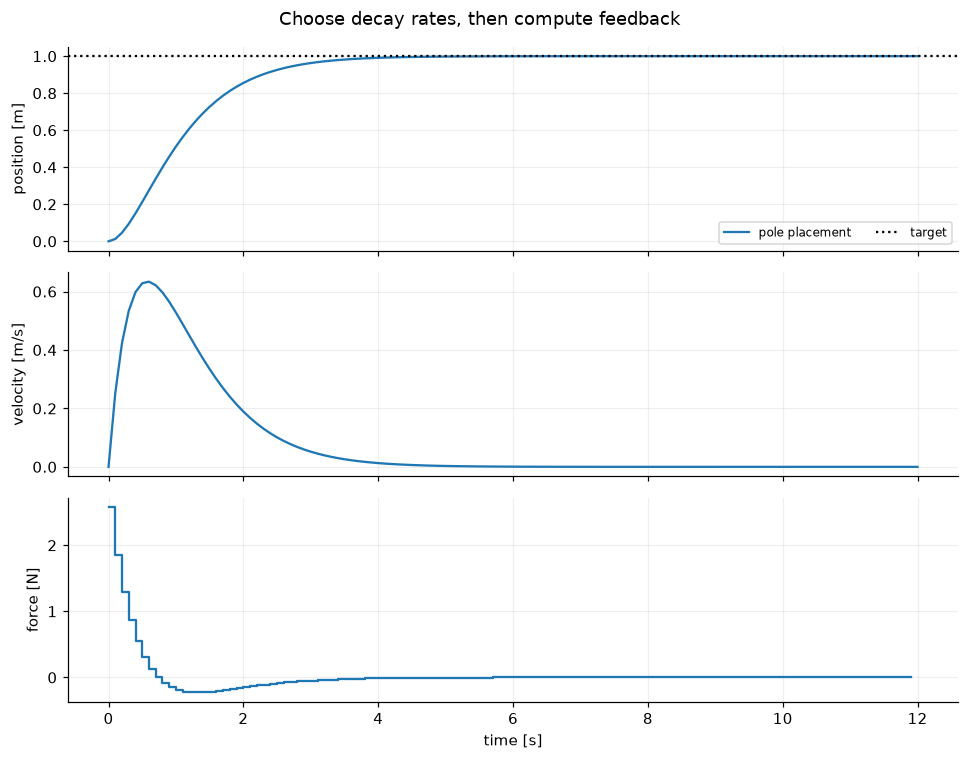

In [3]:
desired = np.exp(np.array([-1.5, -2.0])*DT)
K_place = signal.place_poles(A, B, desired).gain_matrix
print("K from pole placement:", K_place)
print("Closed-loop poles:", np.linalg.eigvals(A-B@K_place))
assert np.allclose(np.sort(np.linalg.eigvals(A-B@K_place)), np.sort(desired))
plot_runs({"pole placement": rollout(lambda x, k: -(K_place@(x-REF)).item())},
          "Choose decay rates, then compute feedback")


## 3. LQR：用一个代价函数表达偏好

线性二次调节器（Linear Quadratic Regulator）对误差系统最小化：

$$J=\sum_{k=0}^{\infty}(e_k^TQe_k+\delta u_k^TR\delta u_k).$$

我们选 $Q=\operatorname{diag}(20,2)$、$R=0.5$：位置偏差、残余速度和输入大小都要付代价。

- 提高位置权重，控制器更愿意用力纠正位置偏差。
- 提高速度权重，控制器更看重停稳。
- 提高输入权重，动作通常更节制，响应可能更慢。

权重有单位和尺度。可先按允许偏差归一化：$q_p\sim1/p_{\mathrm{scale}}^2$、$q_v\sim1/v_{\mathrm{scale}}^2$、$r_u\sim1/u_{\mathrm{scale}}^2$，再调整相对偏好。

这里的 $u^2$ 积分是**控制努力指标**，不是机械能；机械功率是 $uv$。也不要把高位置权重理解为硬边界：再大的有限惩罚仍允许优化器权衡违反程度。


## 4. 从最后一步往前推：Riccati 递推怎么来的？

先考虑有限时域：

$$J_N=\sum_{i=0}^{N-1}(e_i^TQe_i+u_i^TRu_i)+e_N^TP_Ne_N.$$

若从下一步开始的最优代价是 $V_{i+1}(e)=e^TP_{i+1}e$，当前一步的 Bellman 方程是：

$$V_i(e)=\min_u\{e^TQe+u^TRu+(Ae+Bu)^TP_{i+1}(Ae+Bu)\}.$$

对 u 求导并令零：

$$2(R+B^TP_{i+1}B)u+2B^TP_{i+1}Ae=0,$$
$$u_i^*=-K_i e_i,\quad K_i=(R+B^TP_{i+1}B)^{-1}B^TP_{i+1}A.$$

代回得到：

$$P_i=Q+A^TP_{i+1}A-A^TP_{i+1}B(R+B^TP_{i+1}B)^{-1}B^TP_{i+1}A.$$

这就是 Riccati 递推。代码使用线性求解而非显式矩阵求逆。无限时域稳定解满足 $P_i=P_{i+1}=P$，成为离散代数 Riccati 方程（DARE）。

在 $(A,B)$ 可稳定、$(Q^{1/2},A)$ 可检测且 $R\succ0$ 等标准条件下，稳定化解给出稳定的 LQR 反馈。本例完全可控且 $Q\succ0$，满足这些条件。


P =
 [[140.2172  31.7413]
 [ 31.7413  19.6836]]
K = [[5.2586 3.2867]]
LQR poles: [0.8063+0.1185j 0.8063-0.1185j]


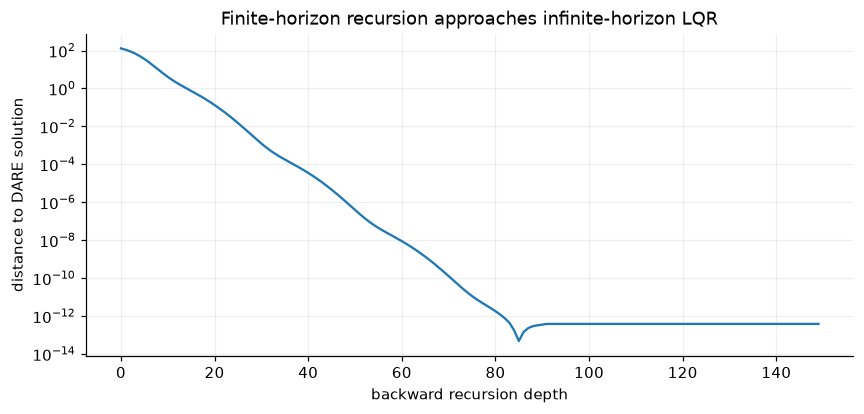

In [4]:
Q = np.diag([20.0, 2.0])
R = np.array([[0.5]])
P = linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.solve(R + B.T @ P @ B, B.T @ P @ A)

print("P =\n", P)
print("K =", K)
closed = A-B@K
print("LQR poles:", np.linalg.eigvals(closed))
assert np.max(np.abs(np.linalg.eigvals(closed))) < 1
assert np.min(np.linalg.eigvalsh(P)) > 0

P_iter = np.zeros((2, 2))
errors = []
for _ in range(150):
    K_iter = np.linalg.solve(R+B.T@P_iter@B, B.T@P_iter@A)
    P_iter = Q + A.T@P_iter@A - A.T@P_iter@B@K_iter
    errors.append(np.linalg.norm(P_iter-P))
assert errors[-1] < 1e-8
plt.semilogy(np.maximum(errors, 1e-15))
plt.xlabel("backward recursion depth")
plt.ylabel("distance to DARE solution")
plt.title("Finite-horizon recursion approaches infinite-horizon LQR")
plt.show()


## 5. 从代价到稳定性：一个可计算的 Lyapunov 函数

对无约束、模型准确的 LQR 闭环，取 $V(e)=e^TPe$。Riccati 方程意味着：

$$(A-BK)^TP(A-BK)-P=-(Q+K^TRK).$$

因此 $V(e_{k+1})-V(e_k)=-e_k^T(Q+K^TRK)e_k<0$（非零 e）。误差“能量”逐步下降，建立渐近稳定性。

这个证明依赖实际执行 $u=-Ke$。把它截断成 $\operatorname{clip}(-Ke,-1,1)$ 后，闭环变成分段非线性，不能原样套用这个矩阵等式作为全局证明。


In [5]:
residual = closed.T@P@closed - P + Q + K.T@R@K
assert np.linalg.norm(residual) < 1e-9
xs, us = rollout(lambda x, k: -(K@(x-REF)).item())
e = xs-REF
values = np.einsum("ni,ij,nj->n", e, P, e)
stage = np.einsum("ni,ij,nj->n", e[:-1], Q, e[:-1]) + R.item()*us**2
assert np.allclose(np.diff(values), -stage, atol=1e-9)
print("Max Lyapunov identity residual:", np.abs(np.diff(values)+stage).max())
print("Finite accumulated cost + final V:", stage.sum()+values[-1])
print("Initial V:", values[0])


Max Lyapunov identity residual: 1.2079226507921703e-13
Finite accumulated cost + final V: 140.2171848937427
Initial V: 140.21718489374237


## 6. 同一辆车，改变偏好会怎样？

先不限制推力，观察 LQR 本身的取舍。再统一截断到 ±1 N。截断之后仍能控制这组初始条件，但它没有规划未来速度和位置约束。


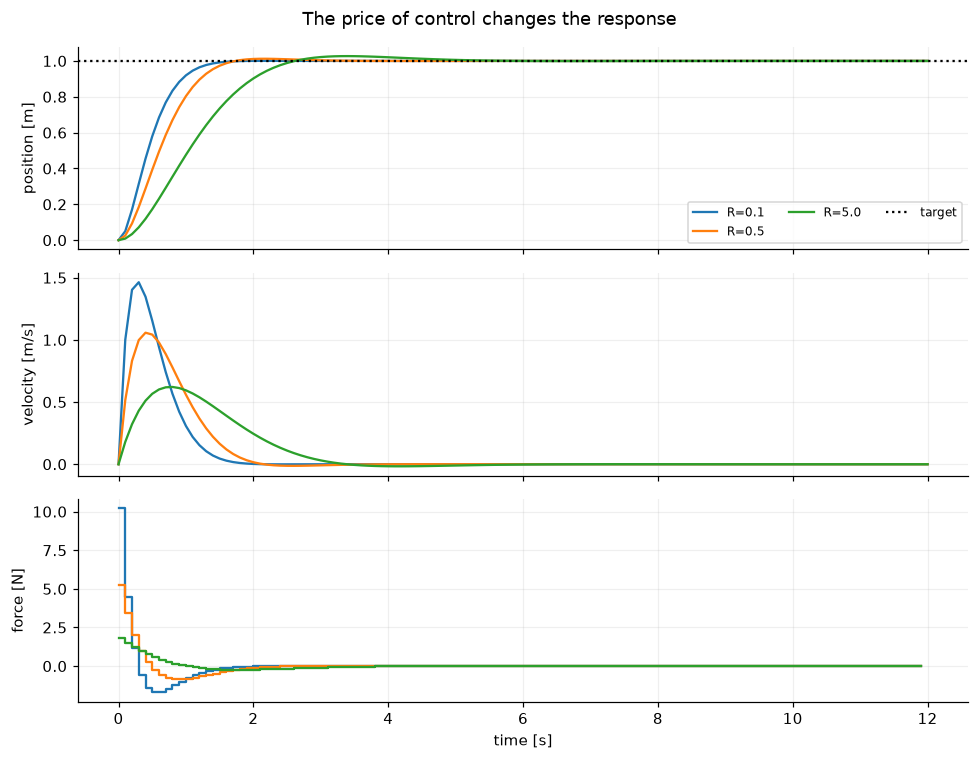

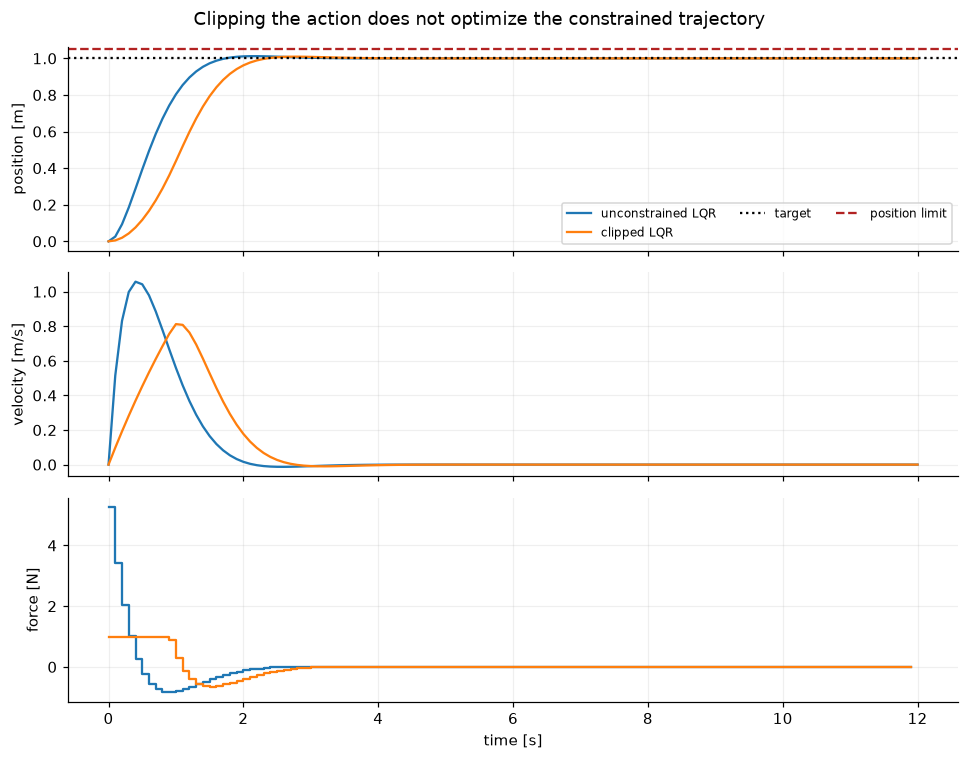

Clipped LQR peak speed: 0.8123240978304245


In [6]:
weight_runs = {}
for r in [0.1, 0.5, 5.0]:
    Pr = linalg.solve_discrete_are(A, B, Q, np.array([[r]]))
    Kr = np.linalg.solve(np.array([[r]])+B.T@Pr@B, B.T@Pr@A)
    weight_runs[f"R={r}"] = rollout(lambda x, k, Kr=Kr: -(Kr@(x-REF)).item())
plot_runs(weight_runs, "The price of control changes the response")

limited = rollout(lambda x, k: np.clip(-(K@(x-REF)).item(), -1, 1))
plot_runs({"unconstrained LQR": (xs, us), "clipped LQR": limited},
          "Clipping the action does not optimize the constrained trajectory", wall=1.05)
print("Clipped LQR peak speed:", np.abs(limited[0][:, 1]).max())


## 7. 小结与自测

| 方法 | 如何选择反馈 | 直接处理什么 |
|---|---|---|
| PD | 由经验、二阶指标、频域等设计增益 | 位置和速度反馈 |
| 极点配置 | 指定闭环特征值 | 自然响应的衰减模式 |
| LQR | 最小化无限时域二次代价 | 状态偏差和控制努力的权衡 |

三者可以长成相似的线性反馈式；差别首先在设计原则。**LQR 本身没有显式状态或输入约束，状态也仍假定已知。**

1. 若只量速度，即 $C=[0,1]$，还能观测绝对位置吗？算可观矩阵的秩。
2. 同时把 Q、R 乘以 10，会改变最优 K 吗？
3. 为什么大 R 与硬输入约束不是一回事？
4. 在 Riccati 递推中将终端矩阵直接设为 DARE 解 P，第一步会发生什么？

<details><summary>参考思路</summary>

1. 不能，位置平移不改变速度测量，可观矩阵秩为 1。2. 不会，代价整体缩放不改变最优解；P 同比缩放。3. 大 R 是软的偏好，足够大的状态误差仍可能产生大输入；硬约束直接禁止。4. P 是不动点，所有步的 K 都与无限时域 LQR 相同；第四篇会数值验证。

</details>

下一步：只有位置传感器时，如何得到状态反馈需要的速度？
